# LOB-Bench with fewer files

The cost of a LOB-Bench evaluation on this cluster is not compute and it is not bytes. It is **file count**. One evaluation writes 25,092 files into `<evaluation>/inference/` on Lustre, the project quota is a fixed number of inodes, and scoring then walks those files again with roughly 12,545 `glob` calls against the metadata server.

This notebook measures what happens when the same tree is stored as a single SquashFS image and read back through a read-only mount. Three claims, each with a figure:

1. the file count, not the byte count, is what runs out;
2. packing reproduces the tree byte for byte, checked per file;
3. the read side gets cheaper rather than more expensive, and needs no change.

Numbers come from `measurements.json` in this directory, recorded from Slurm job 6423589 and from direct timings. Nothing here is recomputed at render time, so the figures and the pull request body cannot disagree.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# 300 dpi because these figures are read on Retina displays and in papers.
plt.rcParams.update({
    "figure.dpi": 300, "savefig.dpi": 300,
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.constrained_layout.use": True,
})
# Inline PNG, not SVG: these are flat-colour bar charts, and the notebook has to
# stay small enough that GitHub still renders it inline.
%config InlineBackend.figure_format = 'png'
INK, ACCENT, WARN, MUTED = "#1f2933", "#2b6cb0", "#c05621", "#a0aec0"

M = json.loads((Path.cwd() / "measurements.json").read_text())
COHORT, INV, QUOTA = M["cohort"], M["inventory"], M["quota"]
FILES_PER_TREE = M["n_files_in_image"]
print(f"measurements taken {M['generated_utc']}")
print(f"cohort: {COHORT['n_trees']} trees from job {COHORT['source_job']}, "
      f"{COHORT['n_pass']} verified")


measurements taken 2026-09-08T23:30:35Z
cohort: 16 trees from job 6423589, 16 verified


## 1. Where the inodes go

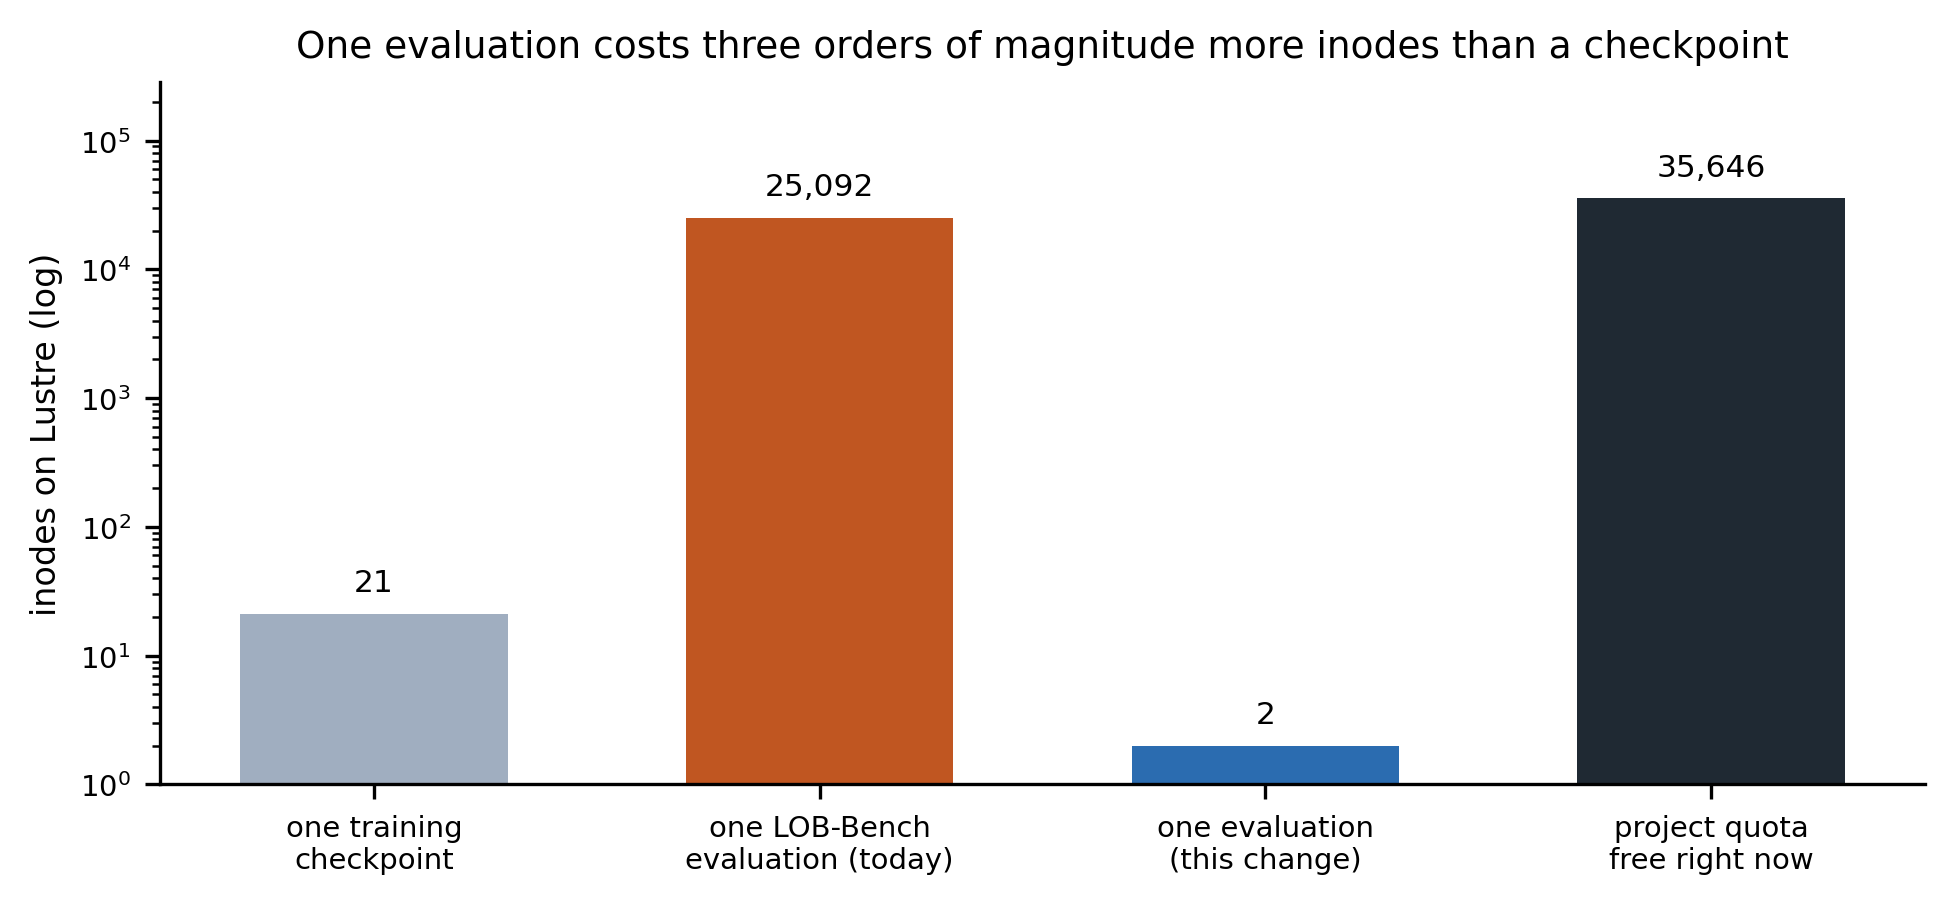

In [2]:
# F1: where the inodes go, per artifact, log scale.
labels = ["one training\ncheckpoint", "one LOB-Bench\nevaluation (today)",
          "one evaluation\n(this change)", "project quota\nfree right now"]
values = [21, FILES_PER_TREE, 2, QUOTA["files_free"]]
colors = [MUTED, WARN, ACCENT, INK]

fig, ax = plt.subplots(figsize=(6.4, 2.9))
bars = ax.bar(labels, values, color=colors, width=0.6)
ax.set_yscale("log")
ax.set_ylabel("inodes on Lustre (log)")
ax.set_title("One evaluation costs three orders of magnitude more inodes than a checkpoint")
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value * 1.35, f"{value:,}",
            ha="center", va="bottom", fontsize=7.5)
ax.set_ylim(1, max(values) * 8)
plt.show()


Stopping training to free resources aims at the wrong resource. A checkpoint is 21 inodes; one evaluation is 25,092, three orders of magnitude more, so the evaluations are the whole problem.

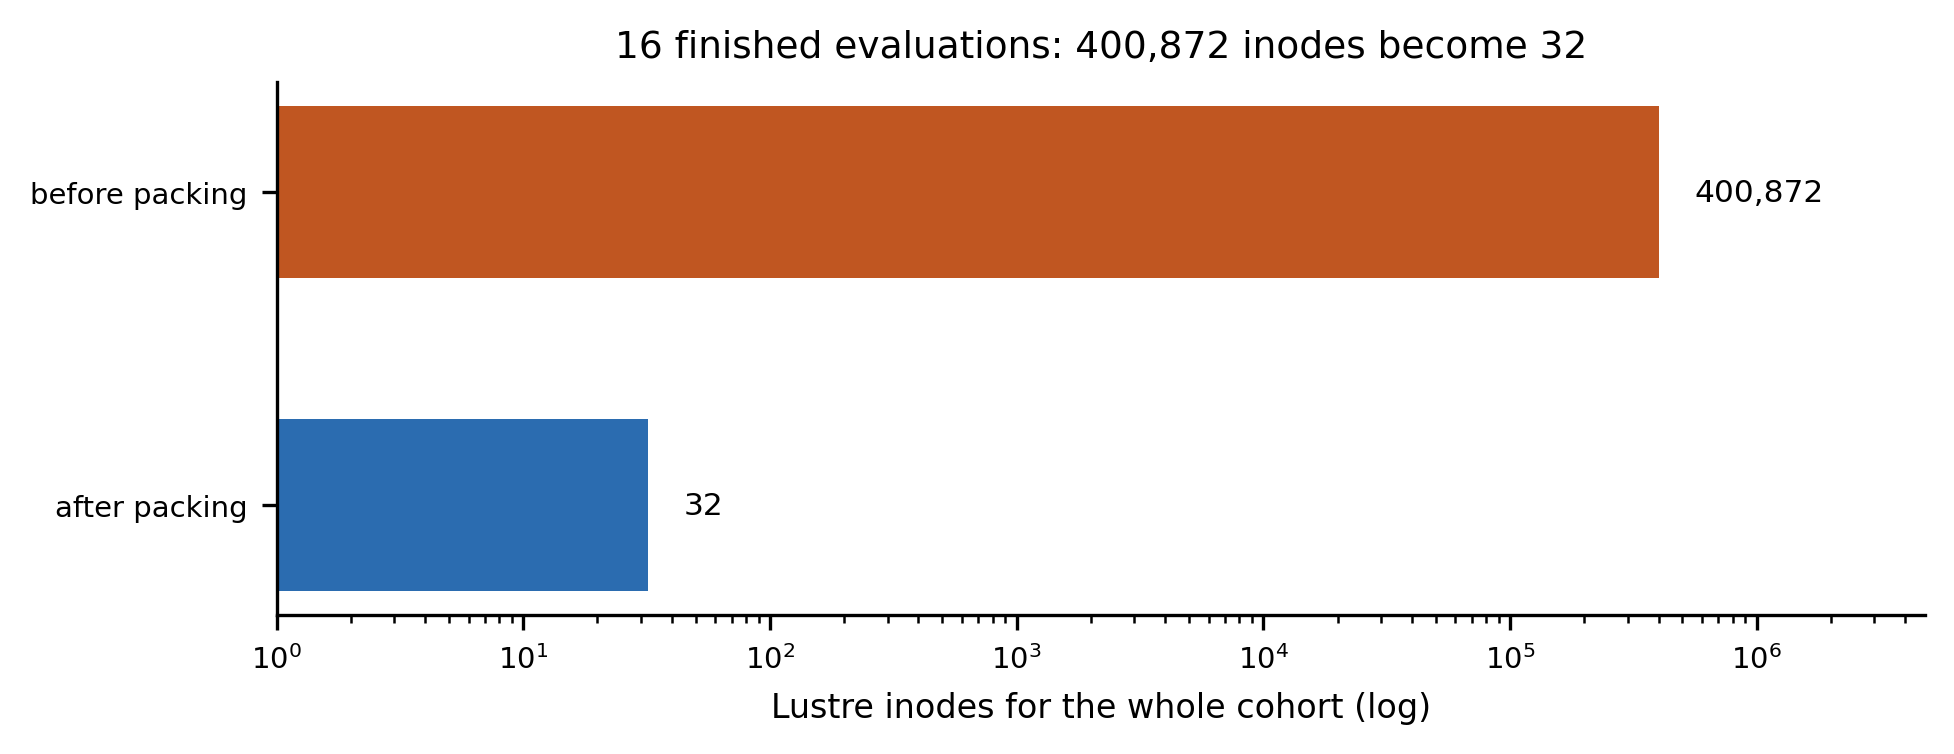

In [3]:
# F2: the same 16 finished trees, before and after packing.
before_files = COHORT["source_files_total"]
after_files = COHORT["n_trees"] * 2          # one image and one sidecar per tree
fig, ax = plt.subplots(figsize=(6.4, 2.4))
ax.barh(["after packing", "before packing"], [after_files, before_files],
        color=[ACCENT, WARN], height=0.55)
ax.set_xscale("log")
ax.set_xlabel("Lustre inodes for the whole cohort (log)")
ax.set_title(f"{COHORT['n_trees']} finished evaluations: {before_files:,} inodes "
             f"become {after_files:,}")
for y, value in zip([0, 1], [after_files, before_files]):
    ax.text(value * 1.4, y, f"{value:,}", va="center", fontsize=7.5)
ax.set_xlim(1, before_files * 12)
plt.show()


The 16 evaluations that already exist hold 400,872 inodes between them; as images they need 32.

## 2. What packing costs and what it preserves

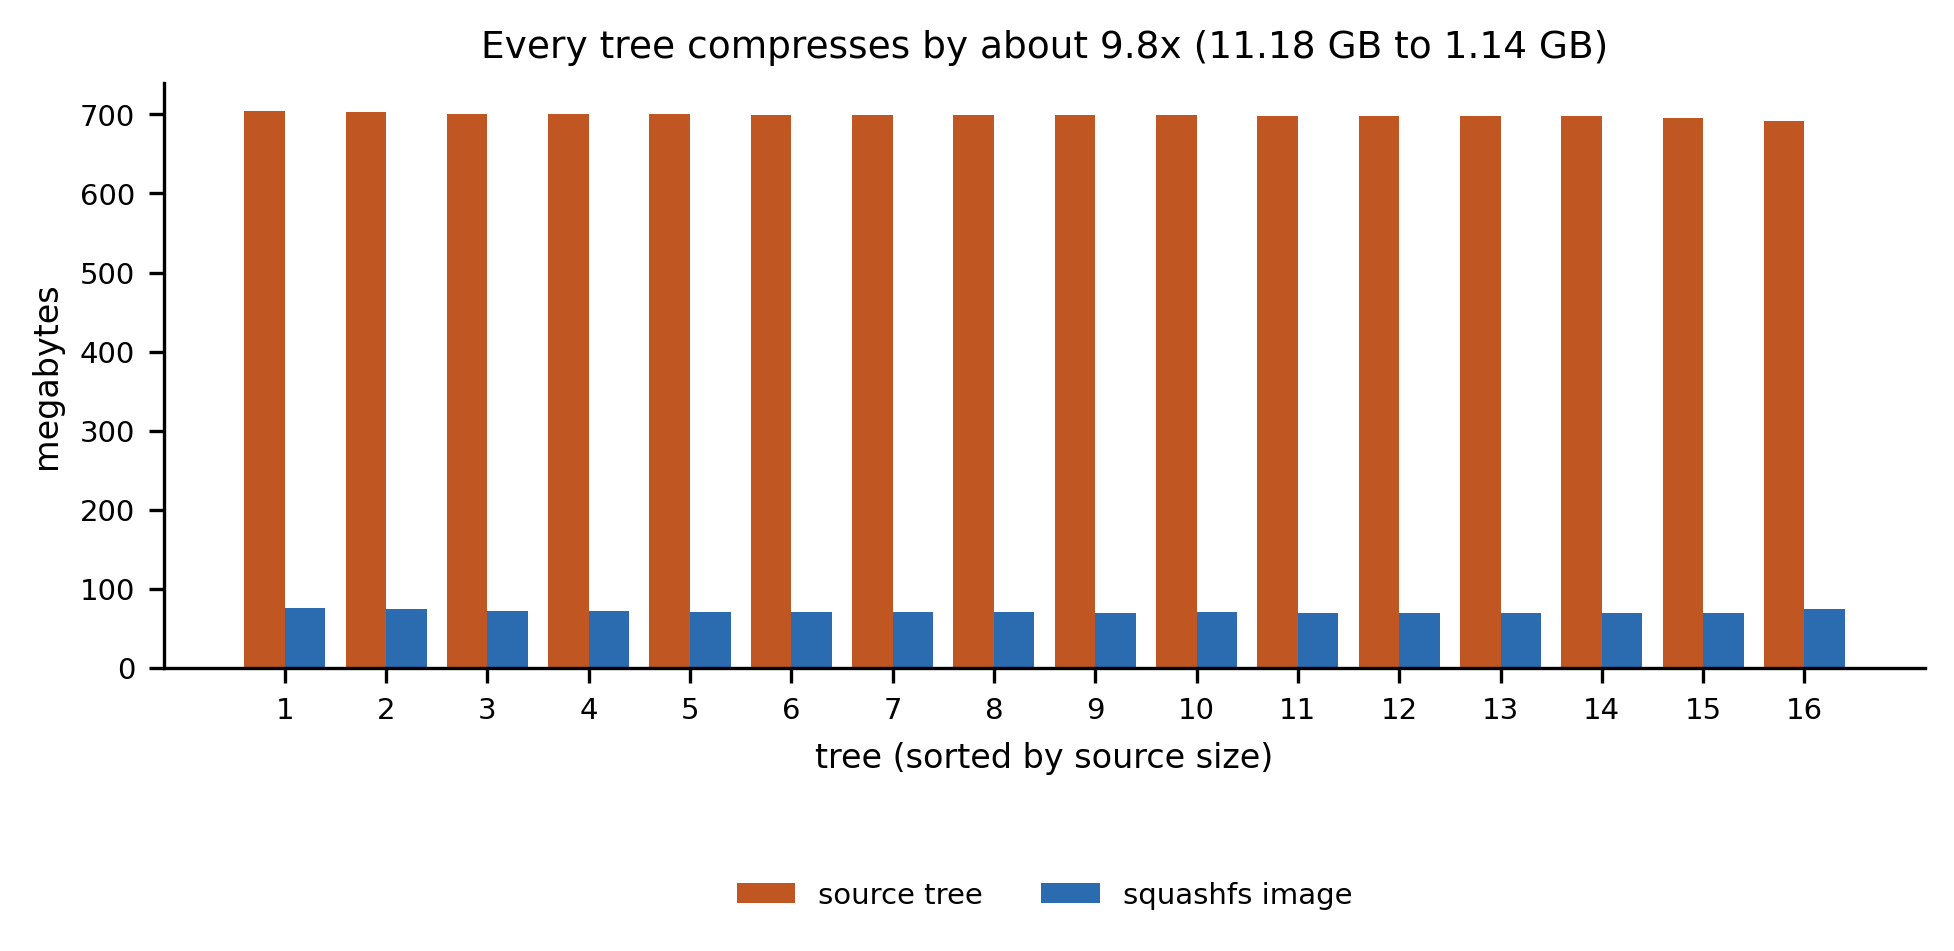

In [4]:
# F3: bytes per tree, source against image, every tree in the cohort.
src = np.array([t["source_bytes"] for t in COHORT["per_tree"]]) / 1e6
img = np.array([t["image_bytes"] for t in COHORT["per_tree"]]) / 1e6
order = np.argsort(-src)
x = np.arange(len(src))

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.bar(x - 0.2, src[order], width=0.4, color=WARN, label="source tree")
ax.bar(x + 0.2, img[order], width=0.4, color=ACCENT, label="squashfs image")
ax.set_xticks(x)
ax.set_xticklabels([f"{i + 1}" for i in x])
ax.set_xlabel("tree (sorted by source size)")
ax.set_ylabel("megabytes")
ratio = COHORT["source_bytes_total"] / COHORT["image_bytes_total"]
ax.set_title(f"Every tree compresses by about {ratio:.1f}x "
             f"({COHORT['source_bytes_total']/1e9:.2f} GB to "
             f"{COHORT['image_bytes_total']/1e9:.2f} GB)")
# below the panel: every bar is near 700 MB, so any in-axes corner collides
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)
plt.show()


Compression is uniform across trees, so the ratio is a property of the data rather than of one lucky tree.

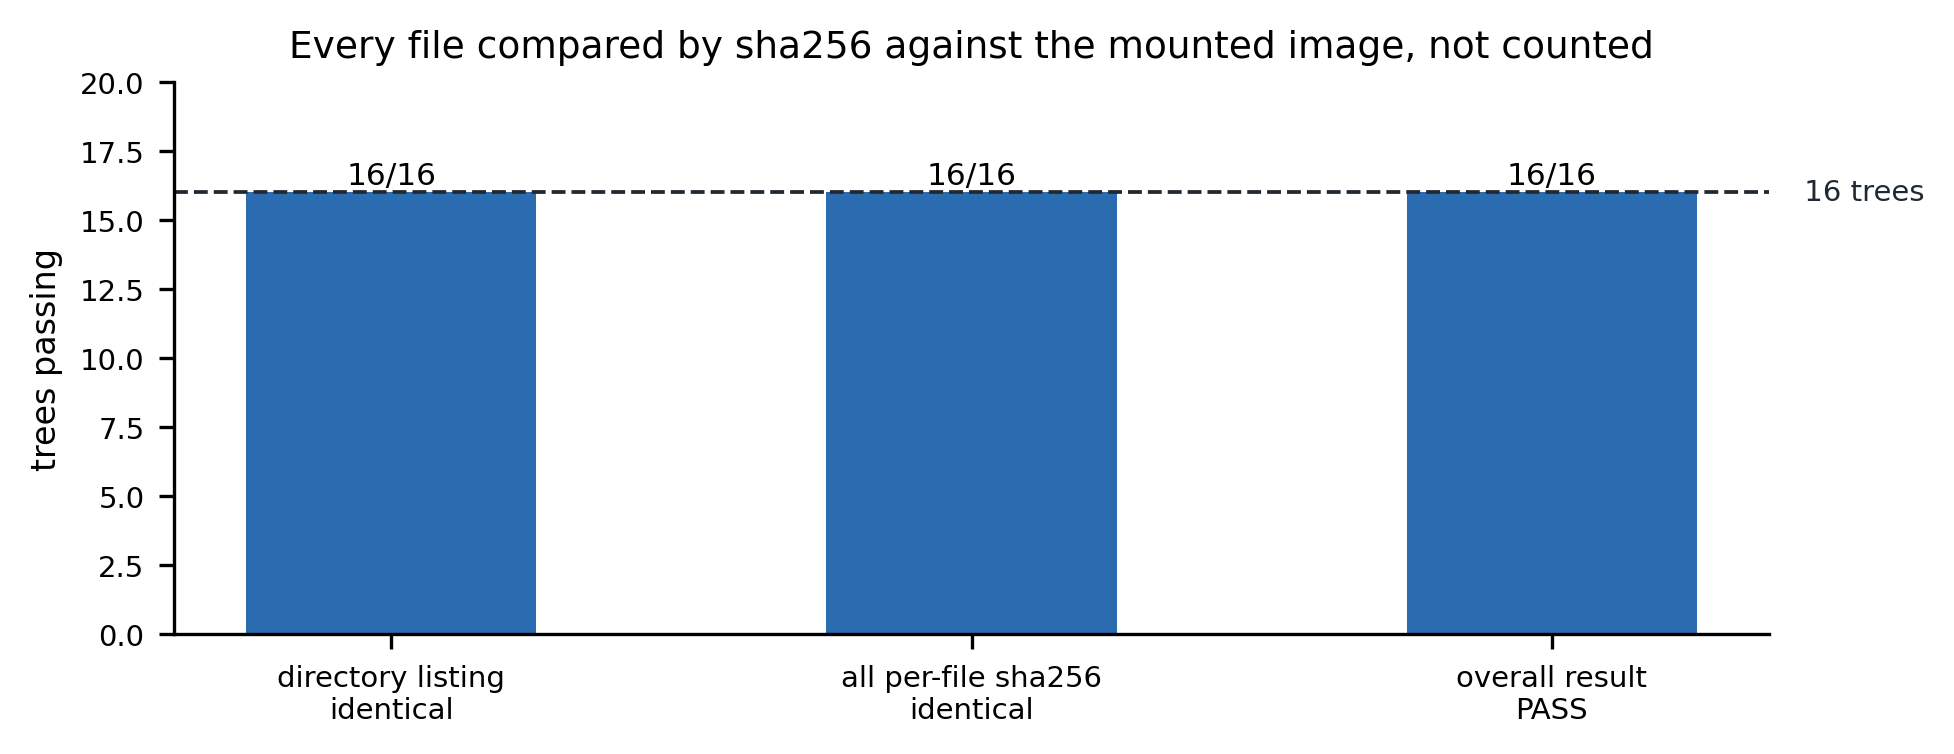

In [5]:
# F4: verification. Both checks, every tree, before anything is trusted.
checks = ["directory listing\nidentical", "all per-file sha256\nidentical",
          "overall result\nPASS"]
passed = [
    sum(1 for t in COHORT["per_tree"] if COHORT["listing_identical_all"]),
    sum(1 for t in COHORT["per_tree"] if COHORT["sha256_identical_all"]),
    COHORT["n_pass"],
]
fig, ax = plt.subplots(figsize=(6.4, 2.4))
bars = ax.bar(checks, passed, color=ACCENT, width=0.5)
ax.axhline(COHORT["n_trees"], color=INK, lw=0.9, ls="--")
ax.text(2.42, COHORT["n_trees"], f" {COHORT['n_trees']} trees", va="center",
        fontsize=7, color=INK)
ax.set_ylabel("trees passing")
ax.set_ylim(0, COHORT["n_trees"] * 1.25)
ax.set_title("Every file compared by sha256 against the mounted image, not counted")
for bar, value in zip(bars, passed):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.3,
            f"{value}/{COHORT['n_trees']}", ha="center", fontsize=7.5)
plt.show()


This is the check that matters. `mksquashfs` has silently truncated files in this project before, and LOB-Bench parses with `on_bad_lines="skip"` and `ignore_errors=True`, so a truncated tail would be absorbed into a shorter DataFrame and move a score with nothing failing. Equal file counts would not have caught it; every file is compared by sha256 against the mounted image.

## 3. Reading it back

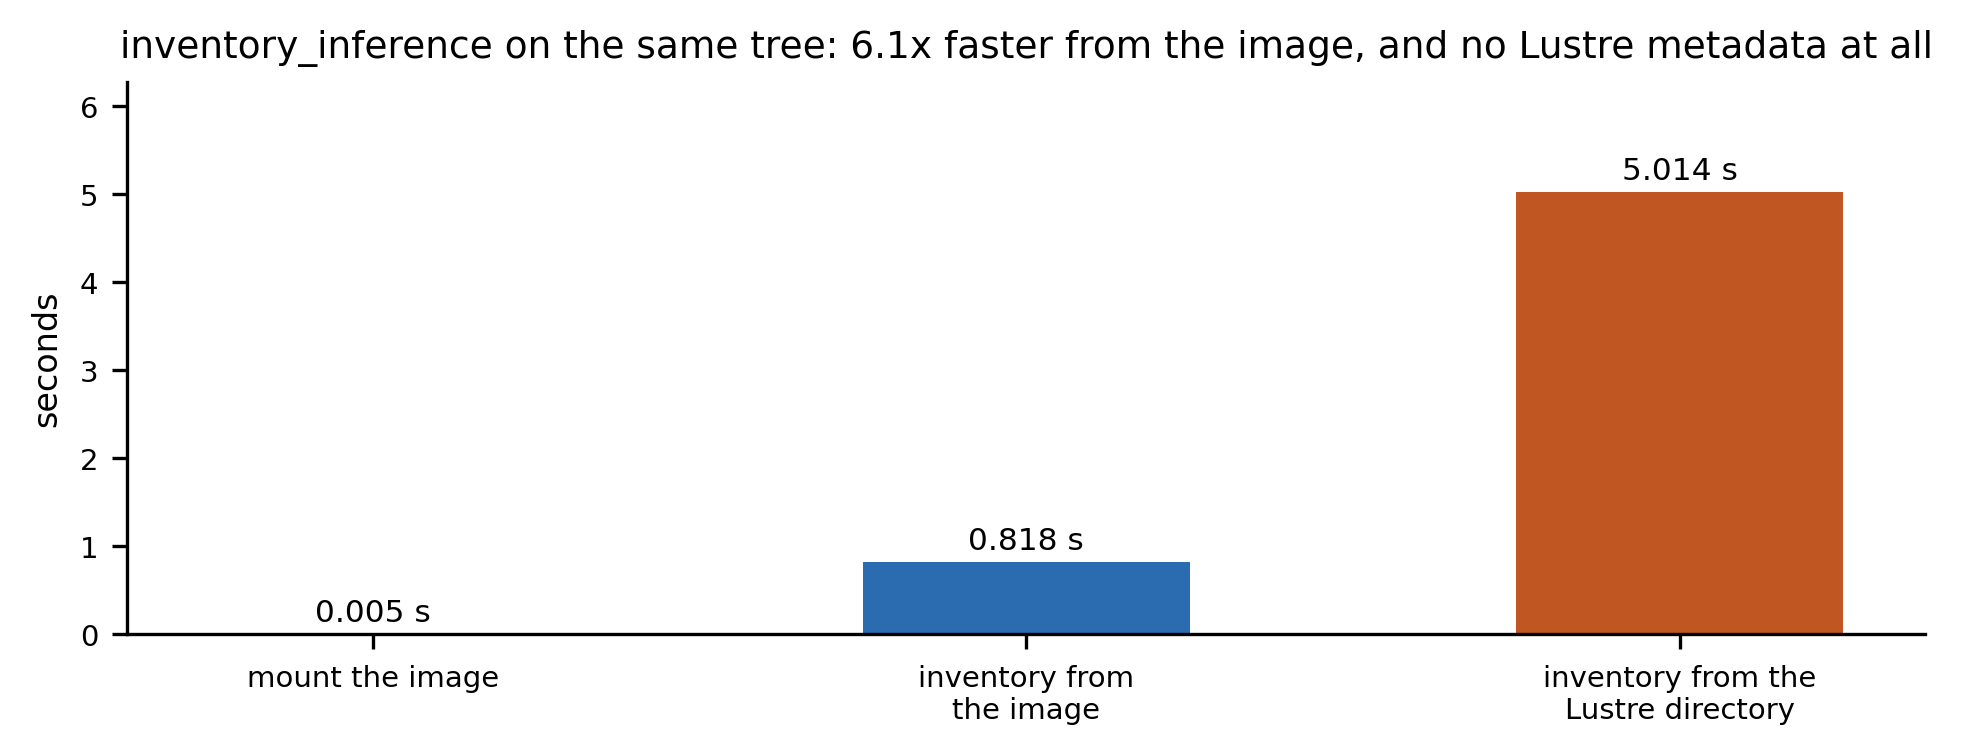

In [6]:
# F5: what the scorer's own inventory costs, image against directory.
names = ["mount the image", "inventory from\nthe image",
         "inventory from the\nLustre directory"]
secs = [INV["mount_seconds"], INV["from_image_seconds"],
        INV["from_lustre_directory_seconds"]]
fig, ax = plt.subplots(figsize=(6.4, 2.4))
bars = ax.bar(names, secs, color=[MUTED, ACCENT, WARN], width=0.5)
ax.set_ylabel("seconds")
speedup = INV["from_lustre_directory_seconds"] / INV["from_image_seconds"]
ax.set_title(f"inventory_inference on the same tree: {speedup:.1f}x faster from the image, "
             f"and no Lustre metadata at all")
for bar, value in zip(bars, secs):
    ax.text(bar.get_x() + bar.get_width() / 2, value + max(secs) * 0.03,
            f"{value:.3f} s", ha="center", fontsize=7.5)
ax.set_ylim(0, max(secs) * 1.25)
plt.show()


The scorer's own `inventory_inference` returns identical counts from the image and from the directory, and is faster from the image while issuing no Lustre metadata operations at all.

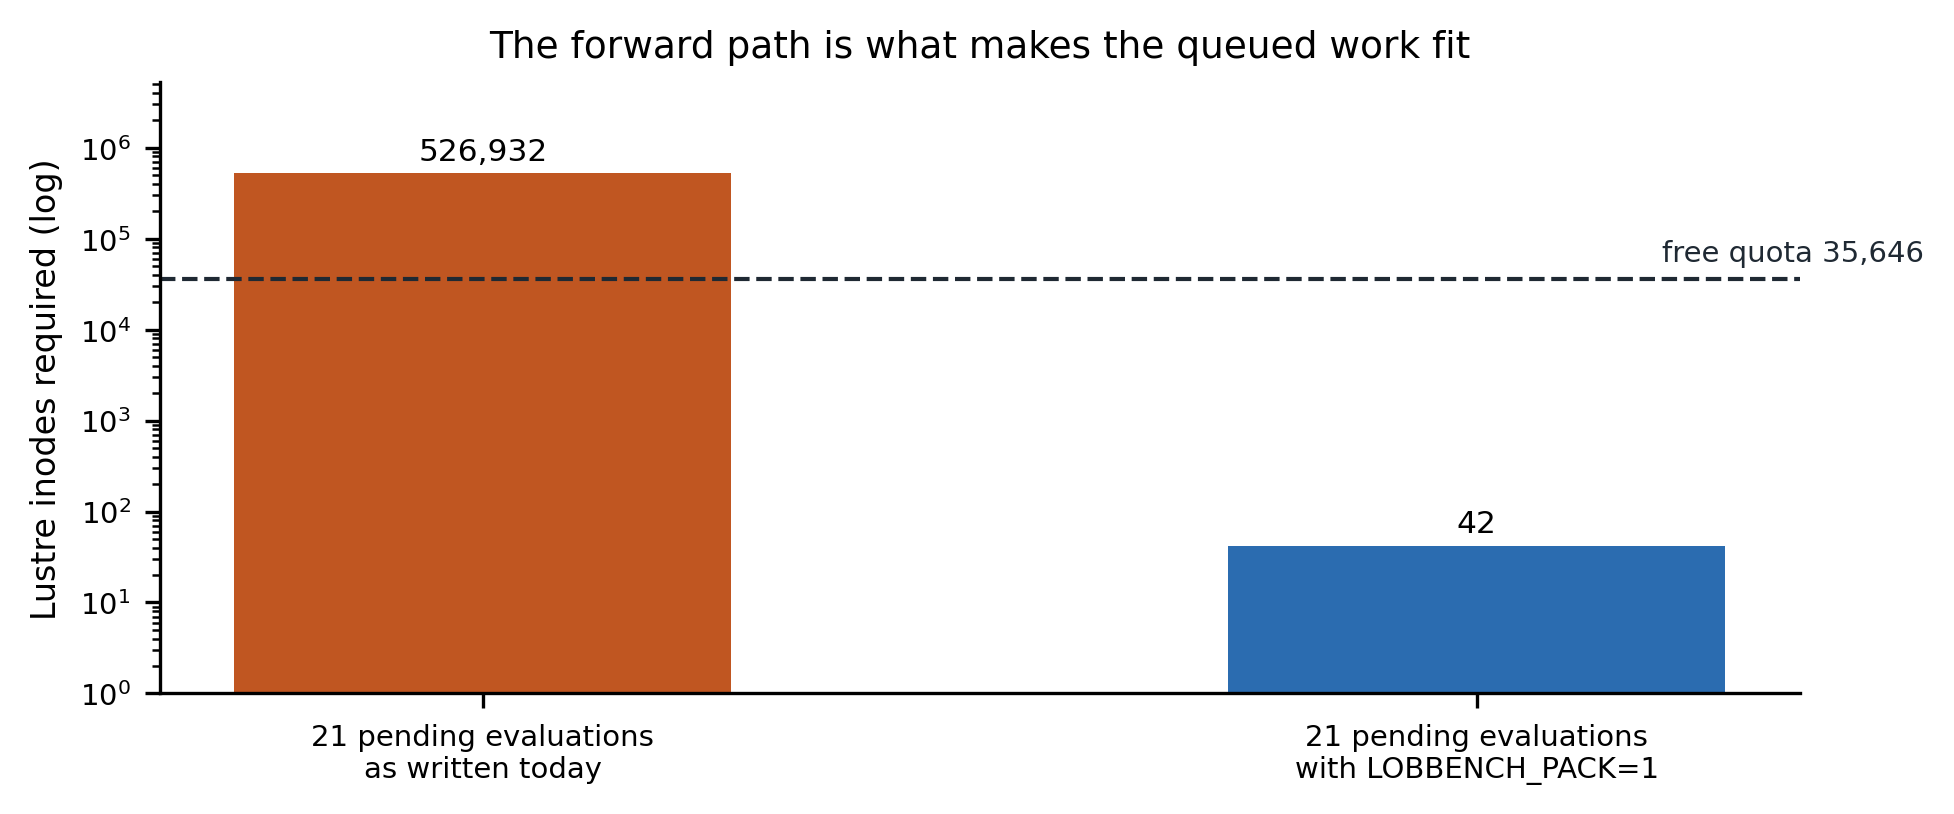

In [7]:
# F6: the forward path, for evaluations not yet run.
pending = 21
fig, ax = plt.subplots(figsize=(6.4, 2.6))
before = pending * FILES_PER_TREE
after = pending * 2
ax.bar(["21 pending evaluations\nas written today",
        "21 pending evaluations\nwith LOBBENCH_PACK=1"],
       [before, after], color=[WARN, ACCENT], width=0.5)
ax.axhline(QUOTA["files_free"], color=INK, lw=1.0, ls="--")
ax.text(1.45, QUOTA["files_free"] * 1.6, f"free quota {QUOTA['files_free']:,}",
        ha="right", fontsize=7, color=INK)
ax.set_yscale("log")
ax.set_ylabel("Lustre inodes required (log)")
ax.set_title("The forward path is what makes the queued work fit")
for i, value in enumerate([before, after]):
    ax.text(i, value * 1.4, f"{value:,}", ha="center", fontsize=7.5)
ax.set_ylim(1, before * 10)
plt.show()


Archiving what already exists does not release an inode, because a rename does not free one and this repository does not delete. The queued work fits because of the forward path: with `LOBBENCH_PACK=1` a new evaluation never writes those files to Lustre in the first place.

## 4. Exact values

In [8]:
# T1: the exact numbers behind the figures.
ratio_bytes = COHORT["source_bytes_total"] / COHORT["image_bytes_total"]
rows = [
    ("Trees packed and verified", f"{COHORT['n_pass']} of {COHORT['n_trees']}"),
    ("Source files, whole cohort", f"{COHORT['source_files_total']:,}"),
    ("Source bytes, whole cohort", f"{COHORT['source_bytes_total']/1e9:.2f} GB"),
    ("Image bytes, whole cohort", f"{COHORT['image_bytes_total']/1e9:.2f} GB"),
    ("Compression", f"{ratio_bytes:.2f}x"),
    ("Files in one tree", f"{FILES_PER_TREE:,}"),
    ("Lustre inodes per evaluation, before", f"{FILES_PER_TREE:,}"),
    ("Lustre inodes per evaluation, after", "2 (image + sidecar)"),
    ("Mount time", f"{INV['mount_seconds']*1000:.1f} ms"),
    ("inventory_inference from the image", f"{INV['from_image_seconds']:.3f} s"),
    ("inventory_inference from the directory", f"{INV['from_lustre_directory_seconds']:.3f} s"),
    ("Counts agree, image vs directory", str(INV["counts_match"])),
    ("Project quota free at measurement", f"{QUOTA['files_free']:,} of {QUOTA['files_limit']:,}"),
]
width = max(len(r[0]) for r in rows)
print(f"{'quantity'.ljust(width)}  value")
print(f"{'-'*width}  {'-'*28}")
for name, value in rows:
    print(f"{name.ljust(width)}  {value}")


quantity                                value
--------------------------------------  ----------------------------
Trees packed and verified               16 of 16
Source files, whole cohort              400,872
Source bytes, whole cohort              11.18 GB
Image bytes, whole cohort               1.14 GB
Compression                             9.82x
Files in one tree                       25,092
Lustre inodes per evaluation, before    25,092
Lustre inodes per evaluation, after     2 (image + sidecar)
Mount time                              4.7 ms
inventory_inference from the image      0.818 s
inventory_inference from the directory  5.014 s
Counts agree, image vs directory        True
Project quota free at measurement       35,646 of 51,200,000


In [9]:
# T2: the file families actually present, read from the image.
fams = M["families"]
width = max(len(k) for k in fams)
print(f"{'family'.ljust(width)}  count")
print(f"{'-'*width}  {'-'*6}")
for name, count in sorted(fams.items()):
    print(f"{name.ljust(width)}  {count:,}")
print()
print(f"total {sum(fams.values()):,} files, {len(fams)} families")


family                                                 count
-----------------------------------------------------  ------
data_cond/GOOG_#-#-#_message_real_id_#.csv             3,136
data_cond/GOOG_#-#-#_orderbook_real_id_#.csv           3,136
data_gen/GOOG_#-#-#_audit_real_id_#_gen_id_#.npz       3,136
data_gen/GOOG_#-#-#_message_real_id_#_gen_id_#.csv     3,136
data_gen/GOOG_#-#-#_orderbook_real_id_#_gen_id_#.csv   3,136
data_gen/GOOG_#-#-#_provenance_real_id_#_gen_id_#.csv  3,136
data_real/GOOG_#-#-#_message_real_id_#.csv             3,136
data_real/GOOG_#-#-#_orderbook_real_id_#.csv           3,136
sample_indices_rank#.json                              4

total 25,092 files, 9 families


How many files a sequence produces is not a constant; it varies with the frozen runtime worktree, and counts of 10, 8, 8 and 7 per sequence have all been observed. The packer therefore records the families it found instead of asserting a fixed set, and packs whole directories.

## 5. What is not established here

The end-to-end acceptance, two scoring runs over the same tree (one reading the directory, one reading the mounted image) whose `lobbench_summary.json` agree bit for bit, needs a compute allocation and is not in this notebook. What is established is the layer below it: the bytes are identical per file, and the scorer's own inventory of the mounted image matches both the directory and the counts recorded when the tree was generated.